1. Problem Statement

In [3]:
print("ML Assignment 2")
print("Classification of mushrooms as edible or poisonous")

ML Assignment 2
Classification of mushrooms as edible or poisonous


2. Dataset Description

In [4]:
import pandas as pd
import numpy as np

dataset_url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/mushroom/agaricus-lepiota.data"
)

column_names = [
    "class", "cap-shape", "cap-surface", "cap-color",
    "bruises", "odor", "gill-attachment", "gill-spacing",
    "gill-size", "gill-color", "stalk-shape", "stalk-root",
    "stalk-surface-above-ring", "stalk-surface-below-ring",
    "stalk-color-above-ring", "stalk-color-below-ring",
    "veil-type", "veil-color", "ring-number", "ring-type",
    "spore-print-color", "population", "habitat"
]

df = pd.read_csv(
    dataset_url,
    header=None,
    names=column_names
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [5]:
print("Dataset Information")
print("------------------")

print("Number of instances:", df.shape[0])
print("Number of features:", df.shape[1] - 1)

print("\nFeature names:")
print(df.columns.tolist())

print("\nTarget variable:")
print("class")

print("\nTarget distribution:")
print(df["class"].value_counts())

Dataset Information
------------------
Number of instances: 8124
Number of features: 22

Feature names:
['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']

Target variable:
class

Target distribution:
class
e    4208
p    3916
Name: count, dtype: int64


3. Exploratory Data Analysis

In [6]:
# Calculate class distribution
class_counts = df["class"].value_counts()

class_percentages = (
    df["class"].value_counts(normalize=True) * 100
)

print("Class Distribution")
print("-----------------")

for label in class_counts.index:
    name = "Edible" if label == "e" else "Poisonous"

    print(
        f"{name}: {class_counts[label]} "
        f"({class_percentages[label]:.2f}%)"
    )

Class Distribution
-----------------
Edible: 4208 (51.80%)
Poisonous: 3916 (48.20%)


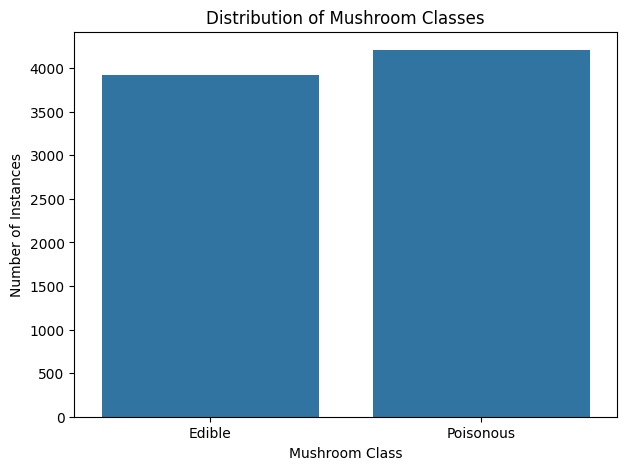

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="class"
)

plt.title("Distribution of Mushroom Classes")
plt.xlabel("Mushroom Class")
plt.ylabel("Number of Instances")

plt.xticks(
    ticks=[0, 1],
    labels=["Edible", "Poisonous"]
)

plt.show()

The Mushroom Classification dataset contains 8,124 instances and 22 input features. The target variable is class, which represents whether a mushroom is edible or poisonous. The dataset contains 4,208 edible mushrooms and 3,916 poisonous mushrooms. The class distribution is approximately balanced, with edible mushrooms representing 51.77% and poisonous mushrooms representing 48.23% of the dataset.

4. Data Preprocessing

### 4.1 Handling Missing Values

The dataset represents missing values using the symbol `?`.
These values are converted to NaN so that they can be identified
and handled during preprocessing.

In [8]:
# Convert '?' to missing values
df.replace("?", np.nan, inplace=True)

# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
stalk-root    2480
dtype: int64

Total missing values: 2480


In [9]:
# Check exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


### 4.2 Handling Duplicate Rows

The dataset contains no exact duplicate rows. Therefore, no
duplicate records were removed.

In [10]:
# Separate target and input features
X = df.drop("class", axis=1)
y = df["class"]

# Check feature data types
print("Feature data types:")
print(X.dtypes)

print("\nNumber of categorical features:", X.select_dtypes(include="object").shape[1])
print("Number of numerical features:", X.select_dtypes(include="number").shape[1])

Feature data types:
cap-shape                   object
cap-surface                 object
cap-color                   object
bruises                     object
odor                        object
gill-attachment             object
gill-spacing                object
gill-size                   object
gill-color                  object
stalk-shape                 object
stalk-root                  object
stalk-surface-above-ring    object
stalk-surface-below-ring    object
stalk-color-above-ring      object
stalk-color-below-ring      object
veil-type                   object
veil-color                  object
ring-number                 object
ring-type                   object
spore-print-color           object
population                  object
habitat                     object
dtype: object

Number of categorical features: 22
Number of numerical features: 0


5. Train-Test Split

### 5.1 Splitting the Dataset

The dataset is divided into 80% training data and 20% testing data.
Stratified sampling is used to maintain the class distribution in
both sets. A fixed random state of 42 ensures reproducibility.

In [11]:
from sklearn.model_selection import train_test_split

# Separate input features and target variable
X = df.drop("class", axis=1)
y = df["class"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training set shape: (6499, 22)
Testing set shape: (1625, 22)

Training class distribution:
class
e    51.792583
p    48.207417
Name: proportion, dtype: float64

Testing class distribution:
class
e    51.815385
p    48.184615
Name: proportion, dtype: float64


6. Model Implementation

### 6.1 Preprocessing Pipeline

All input features are categorical. Missing values are imputed using
the most frequent value, followed by One-Hot Encoding. The encoder
handles previously unseen categories using `handle_unknown="ignore"`.

The preprocessing steps are fitted only on the training data through
a scikit-learn pipeline to prevent data leakage.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identify categorical columns
categorical_features = X_train.columns.tolist()

# Pipeline for categorical features
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply preprocessing to categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")
print("Categorical features:", len(categorical_features))

Preprocessing pipeline created successfully.
Categorical features: 22


### 6.2 Model Implementation

The following five classification algorithms are implemented:

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Multinomial Naive Bayes
5. Random Forest

All models use the same training and testing datasets.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

# Define the classification models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),

    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "KNN": KNeighborsClassifier(n_neighbors=5),

    "Multinomial Naive Bayes": MultinomialNB(),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

print("Five classification models defined successfully.")

for model_name in models:
    print(model_name)

Five classification models defined successfully.
Logistic Regression
Decision Tree
KNN
Multinomial Naive Bayes
Random Forest


### 6.3 Model Training and Evaluation

Each model is trained using the training dataset and evaluated
using the unseen testing dataset.

The following metrics are used:
- Accuracy
- ROC-AUC
- Precision
- Recall
- F1-score
- Matthews Correlation Coefficient (MCC)

The poisonous class (`p`) is treated as the positive class for
Precision, Recall, F1-score, and ROC-AUC.

In [14]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)
import pandas as pd

# Store evaluation results
results = []

# Store trained pipelines
trained_models = {}

for model_name, model in models.items():

    # Create a pipeline with a fresh copy of the preprocessor
    model_pipeline = Pipeline(steps=[
        ("preprocessing", clone(preprocessor)),
        ("classifier", model)
    ])

    # Train the model
    model_pipeline.fit(X_train, y_train)

    # Predict on test data
    y_pred = model_pipeline.predict(X_test)

    # Get probability of poisonous class ('p')
    classifier = model_pipeline.named_steps["classifier"]
    positive_class_index = list(classifier.classes_).index("p")
    y_prob = model_pipeline.predict_proba(X_test)[:, positive_class_index]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    auc = roc_auc_score((y_test == "p").astype(int), y_prob)
    precision = precision_score(y_test, y_pred, pos_label="p", zero_division=0)
    recall = recall_score(y_test, y_pred, pos_label="p", zero_division=0)
    f1 = f1_score(y_test, y_pred, pos_label="p", zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)

    # Save results
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "MCC": mcc
    })

    trained_models[model_name] = model_pipeline

    print(f"{model_name} evaluated successfully.")

# Create a results table
results_df = pd.DataFrame(results)

# Display metrics rounded to 4 decimal places
display(results_df.round(4))

Logistic Regression evaluated successfully.
Decision Tree evaluated successfully.
KNN evaluated successfully.
Multinomial Naive Bayes evaluated successfully.
Random Forest evaluated successfully.


,Model,Accuracy,AUC,Precision,Recall,F1-score,MCC
0,Logistic Regression,0.9988,1.0000,1.0000,0.9974,0.9987,0.9975
1,Decision Tree,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,KNN,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
3,Multinomial Naive Bayes,0.9471,0.9974,0.9888,0.9004,0.9425,0.8970
4,Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


7. Model Evaluation

### 7.1 Evaluation Metrics

The trained classification models were evaluated on the
20% testing dataset, which was not used during model training.

The following evaluation metrics were calculated for each model:

- Accuracy: Proportion of correctly classified observations.
- AUC: Measures the model's ability to distinguish between classes.
- Precision: Proportion of predicted positive cases that are truly positive.
- Recall: Proportion of actual positive cases correctly identified.
- F1-score: Harmonic mean of Precision and Recall.
- MCC: Balanced measure of the quality of binary classification.

The poisonous class (`p`) is considered the positive class
for Precision, Recall, F1-score and AUC.

In [16]:
# Display the evaluation results for all models
evaluation_table = results_df[
    ["Model", "Accuracy", "AUC", "Precision",
     "Recall", "F1-score", "MCC"]
].copy()

evaluation_table = evaluation_table.round(4)

display(evaluation_table)

,Model,Accuracy,AUC,Precision,Recall,F1-score,MCC
0,Logistic Regression,0.9988,1.0000,1.0000,0.9974,0.9987,0.9975
1,Decision Tree,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,KNN,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
3,Multinomial Naive Bayes,0.9471,0.9974,0.9888,0.9004,0.9425,0.8970
4,Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


8. Performance Visualization

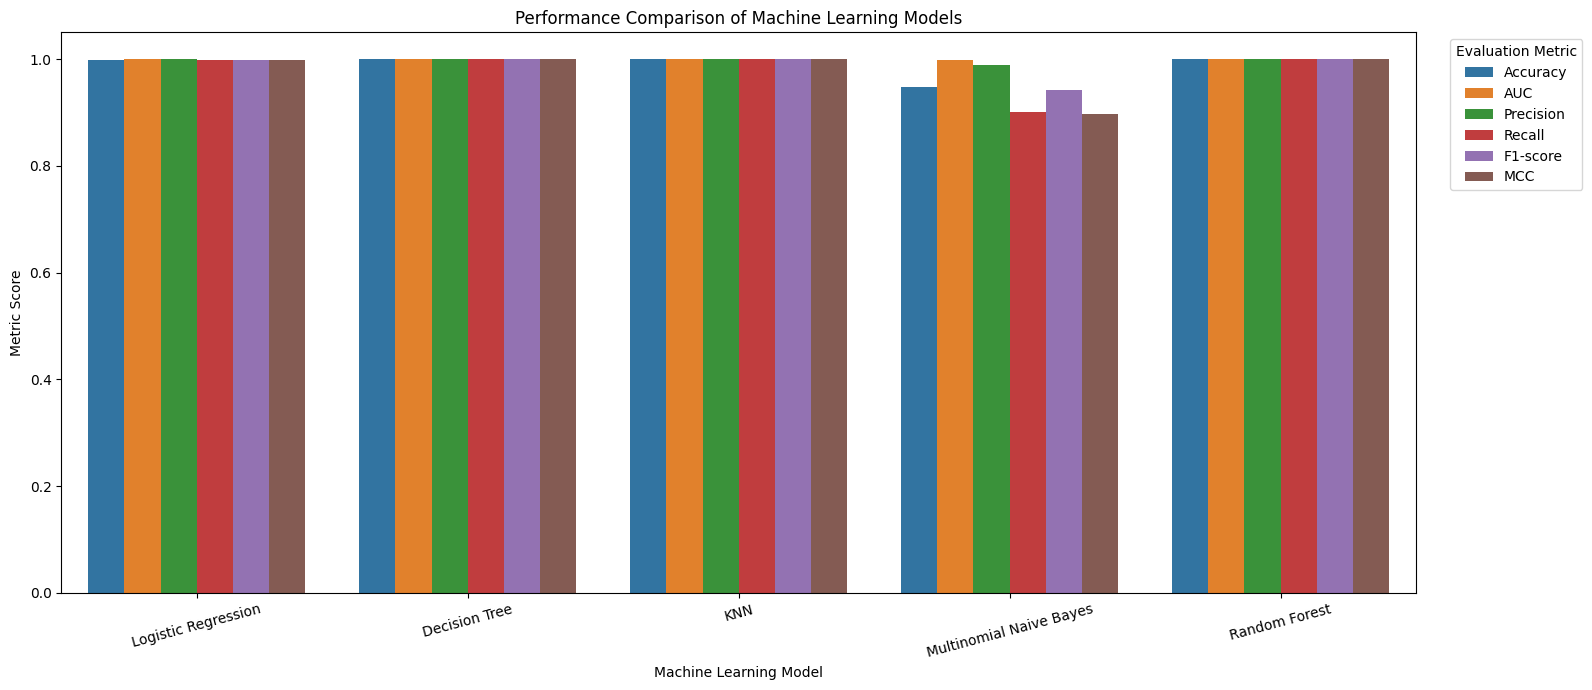

In [17]:
# Compare all models using the six evaluation metrics

metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1-score",
    "MCC"
]

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(16, 7))

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Performance Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Metric Score")
plt.ylim(0, 1.05)

plt.xticks(rotation=15)
plt.legend(title="Evaluation Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

9. Model Comparison and Observations

### 9.1 Logistic Regression

Logistic Regression achieved 99.88% accuracy and an AUC of 1.0000. Its precision was 1.0000 and recall was 0.9974. The model performed very well and misclassified only a very small number of samples.

### 9.2 Decision Tree

Decision Tree achieved 100% in all six evaluation metrics. It correctly classified all the samples in the test dataset. However, the model may overfit, so its performance should also be checked on other data.

### 9.3 K-Nearest Neighbors (KNN)

KNN achieved 100% in all six evaluation metrics. This shows that the model classified the test samples correctly based on their similarity to the training samples. However, KNN can take more time to make predictions when the dataset becomes larger.

### 9.4 Multinomial Naive Bayes

Multinomial Naive Bayes achieved 94.71% accuracy and an AUC of 0.9974. Its recall was 0.9004, which was lower than the other models. This means that the model missed some actual poisonous mushroom samples.

### 9.5 Random Forest

Random Forest achieved 100% in all six evaluation metrics. It performed very well on the test dataset. Since it combines multiple decision trees, it can capture different patterns in the data. Its results were tied with Decision Tree and KNN.

### 9.6 Overall Model Comparison

Decision Tree, KNN and Random Forest were the best-performing models in this experiment, with 100% scores across all six evaluation metrics. Logistic Regression also showed excellent performance, while Multinomial Naive Bayes had comparatively lower scores.

These results are based on one train-test split. Perfect test scores do not guarantee that the models will perform equally well on all unseen data. Further testing can help evaluate their performance more reliably.

10. Save the Test Dataset.

In [18]:
# Save the test dataset

test_data = X_test.copy()
test_data["class"] = y_test

test_data.to_csv("test_data.csv", index=False)

print("Test dataset saved successfully.")
print("Dataset shape:", test_data.shape)

Test dataset saved successfully.
Dataset shape: (1625, 23)


11. Save the Trained Models

In [19]:
import os
import joblib

# Create a folder to store the models
os.makedirs("model", exist_ok=True)

# Save all five trained model pipelines
for model_name, pipeline in trained_models.items():
    file_name = model_name.lower().replace(" ", "_") + ".joblib"
    file_path = os.path.join("model", file_name)

    joblib.dump(pipeline, file_path)

    print("Saved:", file_path)

Saved: model/logistic_regression.joblib
Saved: model/decision_tree.joblib
Saved: model/knn.joblib
Saved: model/multinomial_naive_bayes.joblib
Saved: model/random_forest.joblib


12. Save Model Evaluation Results

In [20]:
# Save model evaluation results

results_df.to_csv("model_results.csv", index=False)

print("Model evaluation results saved successfully.")

Model evaluation results saved successfully.


In [21]:
import os

print("Files in current directory:")

for item in os.listdir("."):
    print(item)

Files in current directory:
.config
model_results.csv
model
test_data.csv
sample_data


In [22]:
# Create requirements.txt

requirements = """pandas
numpy
scikit-learn
matplotlib
seaborn
joblib
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print("requirements.txt created successfully.")

requirements.txt created successfully.


In [25]:
readme_content = '''
# Mushroom Classification Using Machine Learning

## 1. Problem Statement

The aim of this project is to classify mushrooms as edible or poisonous
using their physical characteristics. Five machine learning classification
models are trained and evaluated to compare their performance.

## 2. Dataset Description

The Mushroom dataset is obtained from the UCI Machine Learning Repository.

Dataset source:
https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data

The dataset contains 8124 instances and 22 input features.
The target variable is class.

Target classes:
- e: Edible
- p: Poisonous

All input features are categorical. Missing values represented by ?
were handled during preprocessing.

Class distribution:
- Edible: 4208 samples (51.77%)
- Poisonous: 3916 samples (48.23%)

The classes are fairly balanced.

## 3. GitHub Repository

Repository link: To be added after creating the GitHub repository.

## 4. Data Preprocessing

- Missing values represented by ? were converted to missing values.
- Missing categorical values were replaced using the most frequent value.
- Categorical features were converted using One-Hot Encoding.
- The dataset was split into 80% training and 20% testing data.
- Stratified splitting maintained the class distribution.
- Random state 42 was used for reproducibility.
- Preprocessing was fitted only on training data to avoid data leakage.

## 5. Machine Learning Models

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Multinomial Naive Bayes
5. Random Forest

## 6. Model Evaluation

The models were evaluated using Accuracy, AUC, Precision, Recall,
F1-score and Matthews Correlation Coefficient (MCC).

The poisonous class (p) was considered the positive class for
Precision, Recall and F1-score.

### Model Comparison Results

| Model | Accuracy | AUC | Precision | Recall | F1-score | MCC |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.9988 | 1.0000 | 1.0000 | 0.9974 | 0.9987 | 0.9975 |
| Decision Tree | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| KNN | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| Multinomial Naive Bayes | 0.9471 | 0.9974 | 0.9888 | 0.9004 | 0.9425 | 0.8970 |
| Random Forest | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |

## 7. Performance Visualization

A grouped bar chart was created to compare all five models across
the six evaluation metrics.

## 8. Observations

Decision Tree, KNN and Random Forest achieved perfect scores across
all six metrics on the test dataset.

Logistic Regression also performed very well, with an accuracy of 99.88%.

Multinomial Naive Bayes had comparatively lower performance, especially
in recall. Its recall of 0.9004 indicates that some actual poisonous
mushrooms were missed by the model.

The results are based on one train-test split. Perfect test scores do
not guarantee the same performance on all unseen data.

## 9. Project Files

- test_data.csv: Test dataset used for evaluation.
- model_results.csv: Evaluation results of all five models.
- requirements.txt: Required Python libraries.
- model/: Saved trained model pipelines.
- README.md: Project description and results.

## 10. How to Run

Install the required libraries using:

pip install -r requirements.txt

Open the Jupyter Notebook and run the cells in order.
The saved model pipelines can be loaded using the joblib library.
'''

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully.")

README.md created successfully.


In [26]:
import os

print("README preview:\n")

with open("README.md", "r", encoding="utf-8") as file:
    print(file.read()[:1500])

print("\n\nProject files:")

for item in os.listdir("."):
    if item not in [".config", "sample_data"]:
        print(item)

print("\nSaved model files:")

for item in os.listdir("model"):
    print(item)

README preview:


# Mushroom Classification Using Machine Learning

## 1. Problem Statement

The aim of this project is to classify mushrooms as edible or poisonous
using their physical characteristics. Five machine learning classification
models are trained and evaluated to compare their performance.

## 2. Dataset Description

The Mushroom dataset is obtained from the UCI Machine Learning Repository.

Dataset source:
https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data

The dataset contains 8124 instances and 22 input features.
The target variable is class.

Target classes:
- e: Edible
- p: Poisonous

All input features are categorical. Missing values represented by ?
were handled during preprocessing.

Class distribution:
- Edible: 4208 samples (51.77%)
- Poisonous: 3916 samples (48.23%)

The classes are fairly balanced.

## 3. GitHub Repository

Repository link: To be added after creating the GitHub repository.

## 4. Data Preprocessing

- Missin

In [27]:
import os
import zipfile

project_files = [
    "README.md",
    "requirements.txt",
    "test_data.csv",
    "model_results.csv"
]

zip_name = "Mushroom_Classification_Project.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zip_file:

    # Add project files
    for file_name in project_files:
        zip_file.write(file_name, arcname=file_name)

    # Add saved model pipelines
    for root, dirs, files in os.walk("model"):
        for file_name in files:
            file_path = os.path.join(root, file_name)
            zip_file.write(file_path, arcname=file_path)

print("Project ZIP created:", zip_name)

Project ZIP created: Mushroom_Classification_Project.zip


In [28]:
from google.colab import files

files.download("Mushroom_Classification_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>